<a href="https://colab.research.google.com/github/srabani-khuntia/Machine-Learning-Lab/blob/main/Assignment-2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ASSIGNMENT - 2: Exploratory Data Analysis and Data Preprocessing**

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

##### **1. Write about classification dataset with sample of 10 instances. Also define the size of dataset.**

#### **Campus Placement Prediction Dataset**

The Campus Placement Prediction dataset is a student-oriented dataset containing information about students' academic performance, demographic background, skills, internships, projects, work experience, and extracurricular activities.

The primary objective is to predict whether a student gets placed based on the available attributes.

This is a **Binary Classification Problem** because the target attribute, `placed`, represents two possible outcomes:

- 1 – Student is placed.
- 0 – Student is not placed.

The dataset contains approximately 100,000 instances and 26 attributes, including the target variable.

**Dataset Source:** Kaggle – Campus Placement Prediction

https://www.kaggle.com/datasets/likithagedipudi/campus-placement-prediction
https://drive.google.com/file/d/1vkhTMmvt9ZaMYPXYfBAIwOqV72-Kl6fN/view?usp=drive_link


In [2]:
# Loading the classification dataset
from google.colab import files
uploaded = files.upload()

campus_df = pd.read_csv('campus_placement.csv')
print("Dataset loaded successfully!")

Saving campus_placement.csv to campus_placement (1).csv
Dataset loaded successfully!


In [3]:
# Validating if all columns are present
expected_columns = [
    'student_id', 'gender', 'age', 'city_tier',
    'ssc_percentage', 'ssc_board', 'hsc_percentage',
    'hsc_board', 'hsc_stream', 'degree_percentage',
    'degree_field', 'mba_percentage', 'specialization',
    'internships_count', 'projects_count',
    'certifications_count', 'technical_skills_score',
    'soft_skills_score', 'aptitude_score',
    'communication_score', 'work_experience_months',
    'leadership_roles', 'extracurricular_activities',
    'backlogs', 'placed', 'salary_lpa'
]

assert campus_df.shape[0] == 100000, (
    f"Expected 100000 rows, but found {df.shape[0]}"
)
assert campus_df.shape[1] == 26, (
    f"Expected 26 columns, but found {df.shape[1]}"
)
assert campus_df.columns.tolist() == expected_columns, (
    "Column names or their order do not match!"
)
assert campus_df.notna().any().any(), (
    "Dataset contains no valid data. Check the CSV file."
)
print("Dataset validation successful!")

Dataset validation successful!


In [4]:
# 10 sample instances
display(campus_df.head(10))

# Dataset Size
print("Number of Instances:", campus_df.shape[0])
print("Number of Attributes:", campus_df.shape[1])
print("Dataset Size:", campus_df.shape)
print("Memory occupied:", (round(campus_df.memory_usage(deep=True).sum() / (1024**2), 2), "MB"))


,student_id,gender,age,city_tier,ssc_percentage,ssc_board,hsc_percentage,hsc_board,hsc_stream,degree_percentage,...,technical_skills_score,soft_skills_score,aptitude_score,communication_score,work_experience_months,leadership_roles,extracurricular_activities,backlogs,placed,salary_lpa
0,STU000001,Male,22,Tier 1,71.01,State,76.76,CBSE,Commerce,64.44,...,6.8,7.8,62.1,6.2,14,1,10,0,1,12.24
1,STU000002,Female,22,Tier 2,58.46,CBSE,57.62,State,Science,68.24,...,4.6,4.8,58.7,7.2,5,1,4,0,1,10.09
2,STU000003,Female,21,Tier 1,67.83,CBSE,65.67,State,Commerce,52.33,...,4.7,5.0,58.9,5.0,30,2,1,0,1,14.94
3,STU000004,Female,21,Tier 2,80.40,CBSE,77.15,State,Science,56.55,...,6.8,7.6,35.0,8.3,31,0,5,0,1,15.49
4,STU000005,Male,21,Tier 1,66.10,State,62.81,ICSE,Science,78.93,...,7.0,5.7,54.0,5.4,24,0,2,0,1,15.13
5,STU000006,Male,22,Tier 1,71.26,State,67.53,State,Science,54.50,...,5.5,6.2,65.5,4.1,31,0,2,1,1,17.65
6,STU000007,Male,23,Tier 2,51.92,State,55.72,ICSE,Science,45.00,...,4.3,5.0,34.4,5.4,27,0,0,6,0,0.00
7,STU000008,Female,23,Tier 3,84.52,ICSE,77.08,State,Commerce,50.09,...,2.5,4.2,53.9,4.4,0,0,4,1,1,10.17
8,STU000009,Female,21,Tier 2,81.37,CBSE,68.22,CBSE,Commerce,59.62,...,8.7,9.5,47.9,10.0,0,1,3,0,1,9.92
9,STU000010,Female,21,Tier 1,94.13,CBSE,94.66,ICSE,Commerce,84.05,...,7.1,7.4,35.7,6.3,0,0,3,0,1,11.72


Number of Instances: 100000
Number of Attributes: 26
Dataset Size: (100000, 26)
Memory occupied: (np.float64(54.77), 'MB')


##### **2. Write on different attributes, type of attributes, number of instances, number of attributes, number of missing data, describe the dataset of classification.**


#### Attribute Analysis

The Campus Placement Prediction dataset contains 26 attributes describing different aspects of students.

These attributes can be categorized into numerical, categorical, ordinal, and identifier attributes.

- **Numerical attributes:** Represent measurable or countable quantities.
- **Categorical attributes:** Represent labels or groups.
- **Ordinal attributes:** Represent categories having a meaningful order.
- **Identifier attributes:** Uniquely identify individual records.

The dataset contains 100,000 instances and 26 attributes.

In [5]:
# Display all attributes
print("All Attributes:")
for i, col in enumerate(campus_df.columns, start=1):
    print(i, col)

All Attributes:
1 student_id
2 gender
3 age
4 city_tier
5 ssc_percentage
6 ssc_board
7 hsc_percentage
8 hsc_board
9 hsc_stream
10 degree_percentage
11 degree_field
12 mba_percentage
13 specialization
14 internships_count
15 projects_count
16 certifications_count
17 technical_skills_score
18 soft_skills_score
19 aptitude_score
20 communication_score
21 work_experience_months
22 leadership_roles
23 extracurricular_activities
24 backlogs
25 placed
26 salary_lpa


In [6]:
# Display attribute types
print("Attribute Data Types:")
campus_df.dtypes

Attribute Data Types:


,0
student_id,object
gender,object
age,int64
city_tier,object
ssc_percentage,float64
ssc_board,object
hsc_percentage,float64
hsc_board,object
hsc_stream,object
degree_percentage,float64


In [7]:
# Attribute Summary
campus_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 26 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   student_id                  100000 non-null  object 
 1   gender                      100000 non-null  object 
 2   age                         100000 non-null  int64  
 3   city_tier                   100000 non-null  object 
 4   ssc_percentage              100000 non-null  float64
 5   ssc_board                   100000 non-null  object 
 6   hsc_percentage              100000 non-null  float64
 7   hsc_board                   100000 non-null  object 
 8   hsc_stream                  100000 non-null  object 
 9   degree_percentage           100000 non-null  float64
 10  degree_field                100000 non-null  object 
 11  mba_percentage              100000 non-null  float64
 12  specialization              35035 non-null   object 
 13  internships_cou

In [8]:
# 1. Identifier attributes
identifier_attributes = [
    'student_id'
]

# 2. Numerical attributes
numerical_attributes = [
    'age',
    'ssc_percentage',
    'hsc_percentage',
    'degree_percentage',
    'mba_percentage',
    'internships_count',
    'projects_count',
    'certifications_count',
    'technical_skills_score',
    'soft_skills_score',
    'aptitude_score',
    'communication_score',
    'work_experience_months',
    'leadership_roles',
    'extracurricular_activities',
    'backlogs',
    'salary_lpa'
]

# 3. Categorical predictor attributes
categorical_attributes = [
    'gender',
    'city_tier',
    'ssc_board',
    'hsc_board',
    'hsc_stream',
    'degree_field',
    'specialization'
]

# 4. Target attribute
target_attribute = ['placed']

print("IDENTIFIER ATTRIBUTES:")
display(identifier_attributes)

print("\nNUMERICAL ATTRIBUTES:")
display(numerical_attributes)

print("\nCATEGORICAL ATTRIBUTES:")
display(categorical_attributes)

print("\nTARGET ATTRIBUTE:")
display(target_attribute)

print("\nATTRIBUTE COUNT SUMMARY:")
print("Identifier Attributes:", len(identifier_attributes))
print("Numerical Attributes:", len(numerical_attributes))
print("Categorical Attributes:", len(categorical_attributes))
print("Target Attributes:", len(target_attribute))

total = (
    len(identifier_attributes) +
    len(numerical_attributes) +
    len(categorical_attributes) +
    len(target_attribute)
)

print("\nTotal Number of Attributes:", total)


IDENTIFIER ATTRIBUTES:


['student_id']


NUMERICAL ATTRIBUTES:


['age',
 'ssc_percentage',
 'hsc_percentage',
 'degree_percentage',
 'mba_percentage',
 'internships_count',
 'projects_count',
 'certifications_count',
 'technical_skills_score',
 'soft_skills_score',
 'aptitude_score',
 'communication_score',
 'work_experience_months',
 'leadership_roles',
 'extracurricular_activities',
 'backlogs',
 'salary_lpa']


CATEGORICAL ATTRIBUTES:


['gender',
 'city_tier',
 'ssc_board',
 'hsc_board',
 'hsc_stream',
 'degree_field',
 'specialization']


TARGET ATTRIBUTE:


['placed']


ATTRIBUTE COUNT SUMMARY:
Identifier Attributes: 1
Numerical Attributes: 17
Categorical Attributes: 7
Target Attributes: 1

Total Number of Attributes: 26


In [9]:
# Missing values
missing_values = campus_df.isnull().sum()
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': (missing_values / len(campus_df) * 100).round(2)
})

display(missing_summary)
print("Total Missing Values:", missing_values.sum())
print("Total Missing Percentage:", round(missing_values.sum() / campus_df.size * 100, 2), "%")

,Missing Values,Missing Percentage
student_id,0,0.00
gender,0,0.00
age,0,0.00
city_tier,0,0.00
ssc_percentage,0,0.00
ssc_board,0,0.00
hsc_percentage,0,0.00
hsc_board,0,0.00
hsc_stream,0,0.00
degree_percentage,0,0.00


Total Missing Values: 64965
Total Missing Percentage: 2.5 %


In [10]:
# Dataset Description
campus_df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
student_id,100000,100000,STU000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,100000,3,Male,55027,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,100000.0,NaN,NaN,NaN,21.55581,1.50696,18.0,21.0,21.0,22.0,26.0
city_tier,100000,3,Tier 2,40069,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ssc_percentage,100000.0,NaN,NaN,NaN,71.929885,11.867225,40.0,63.87,71.92,80.03,100.0
ssc_board,100000,3,State,50095,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hsc_percentage,100000.0,NaN,NaN,NaN,71.831667,13.903709,40.0,62.12,71.86,81.72,100.0
hsc_board,100000,3,State,50000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hsc_stream,100000,3,Science,49771,NaN,NaN,NaN,NaN,NaN,NaN,NaN
degree_percentage,100000.0,NaN,NaN,NaN,70.18552,15.599274,45.0,58.09,69.89,81.84,100.0


##### **3. Perform the EDA.**

In [11]:
# Check duplicate records
print("Number of Duplicate Rows:",
      campus_df.duplicated().sum())

Number of Duplicate Rows: 0


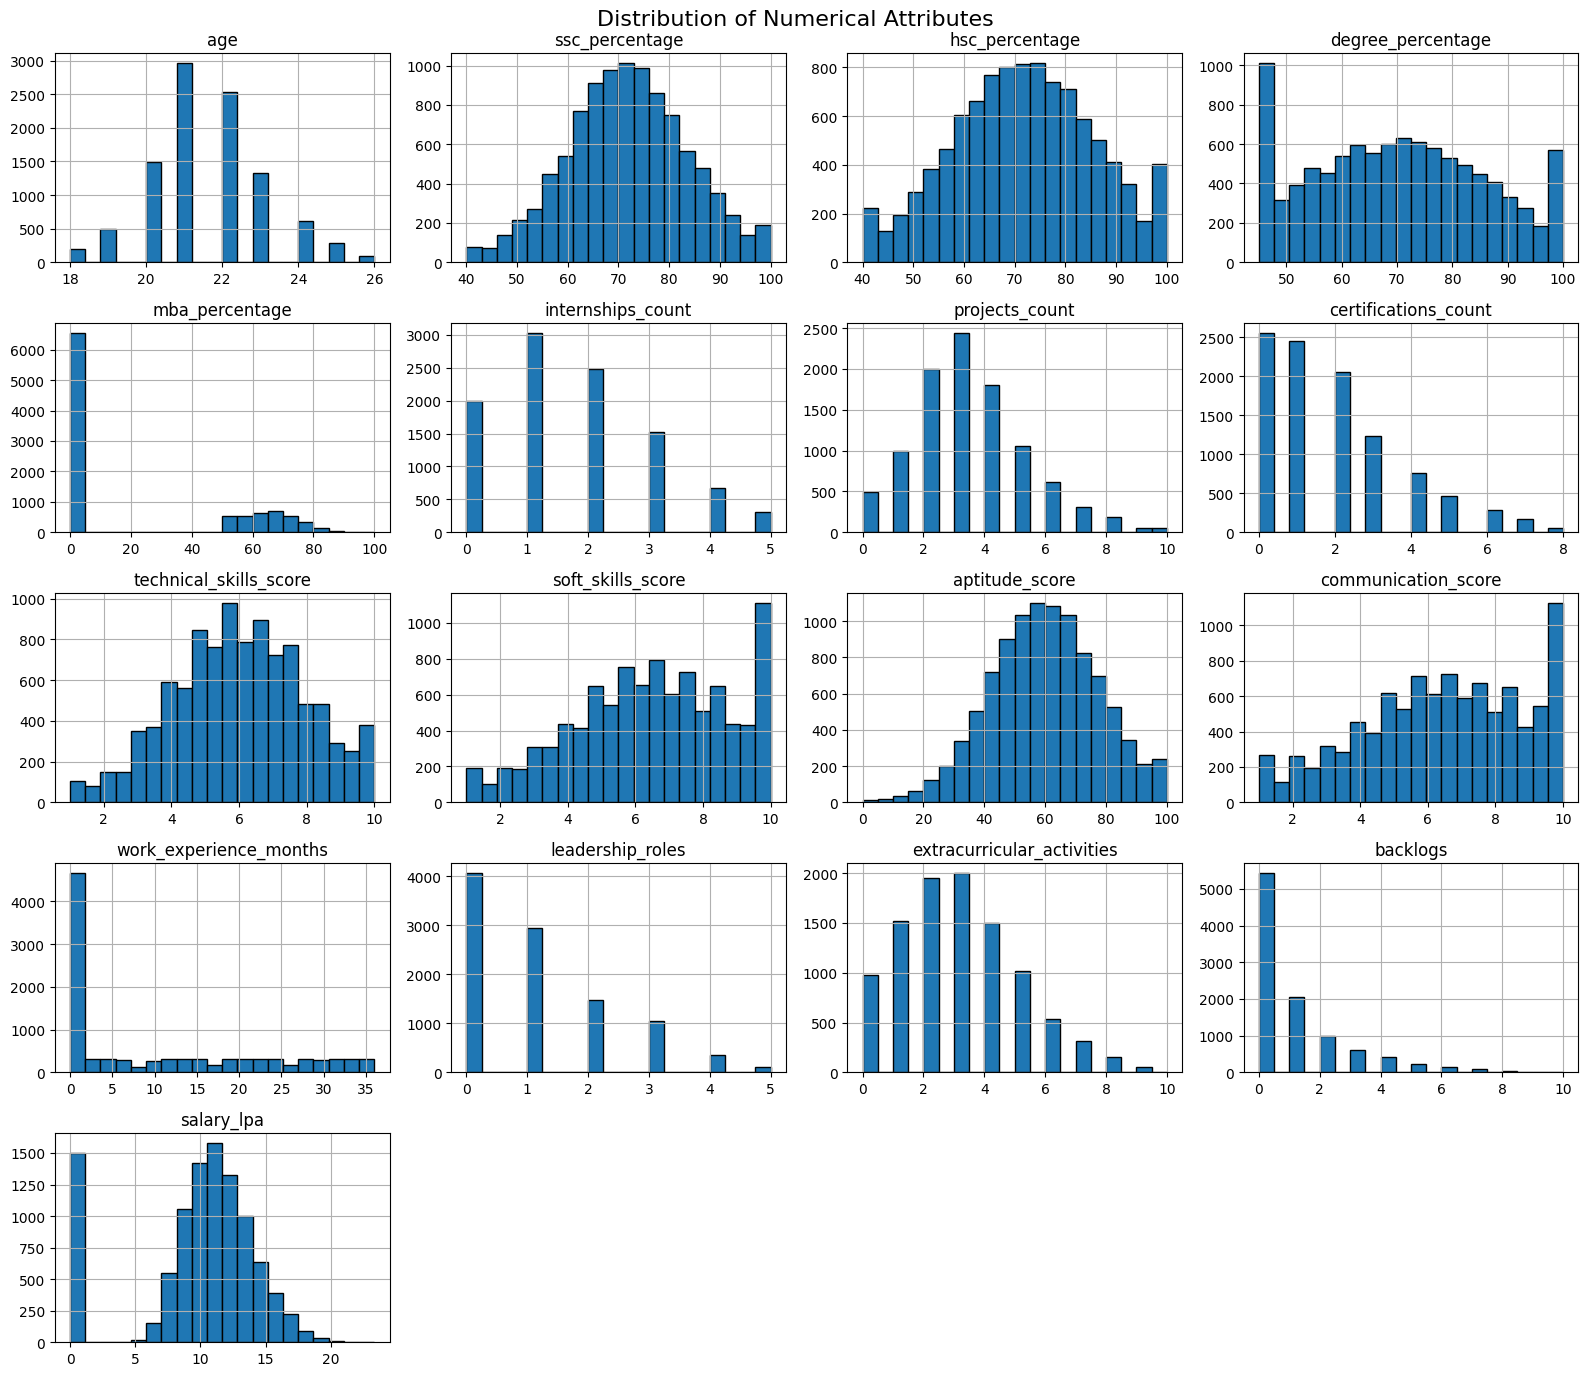

In [12]:
# Numerical attribute distribution
eda_sample = campus_df.sample(
    n=min(10000, len(campus_df)),
    random_state=42
)

eda_sample[numerical_attributes].hist(
    figsize=(16, 14),
    bins=20,
    edgecolor='black'
)

plt.suptitle(
    "Distribution of Numerical Attributes",
    fontsize=16
)

plt.tight_layout()
plt.show()



Attribute: gender
gender
Male      55027
Female    43028
Other      1945
Name: count, dtype: int64

Attribute: city_tier
city_tier
Tier 2    40069
Tier 3    29990
Tier 1    29941
Name: count, dtype: int64

Attribute: ssc_board
ssc_board
State    50095
CBSE     34905
ICSE     15000
Name: count, dtype: int64

Attribute: hsc_board
hsc_board
State    50000
CBSE     34957
ICSE     15043
Name: count, dtype: int64

Attribute: hsc_stream
hsc_stream
Science     49771
Commerce    35049
Arts        15180
Name: count, dtype: int64

Attribute: degree_field
degree_field
Engineering    40019
Business       24946
Science        14876
Other          10147
Arts           10012
Name: count, dtype: int64

Attribute: specialization
specialization
NaN                    64965
Marketing & HR         11741
Finance & HR           11675
Marketing & Finance    11619
Name: count, dtype: int64


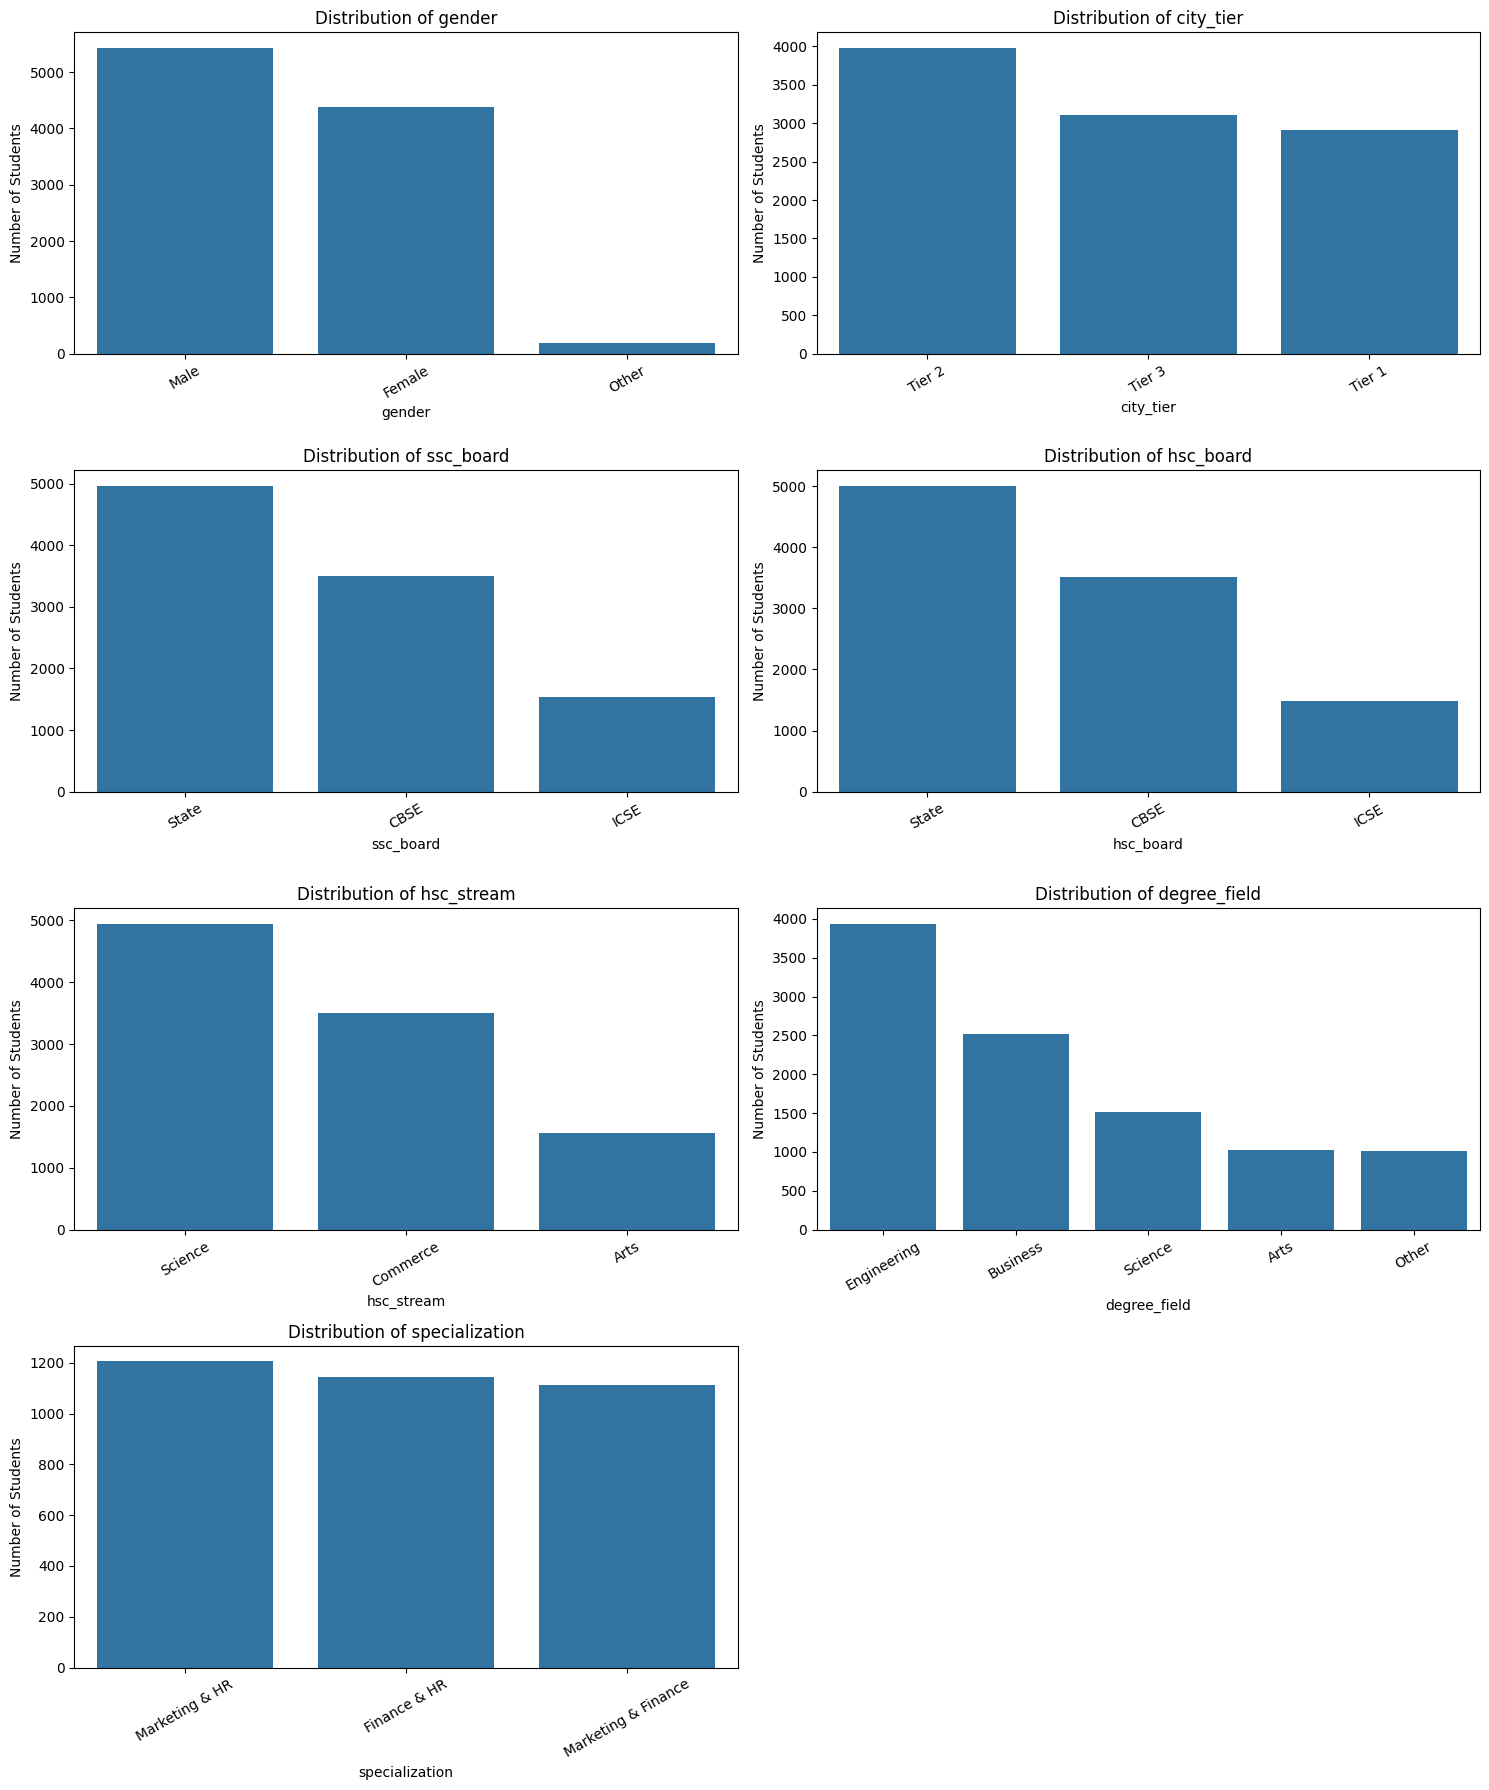

In [13]:
# Categorical attribute distribution
fig, axes = plt.subplots(4, 2, figsize=(15, 18))

for col, ax in zip(categorical_attributes, axes.flatten()):
  print("\nAttribute:", col)
  print(campus_df[col].value_counts(dropna=False))

  sns.countplot(
      data=eda_sample,
      x=col,
      ax=ax,
      order=eda_sample[col].value_counts().index,
  )

  ax.set_title(f"Distribution of {col}")
  ax.set_xlabel(col)
  ax.set_ylabel("Number of Students")
  ax.tick_params(axis="x", rotation=30)

# Hide any unused subplot slots dynamically
for ax in axes.flatten()[len(categorical_attributes) :]:
  ax.set_visible(False)

plt.tight_layout()
plt.show()


Placement Distribution:
placed
0         15568
1         84432
Name: count, dtype: int64


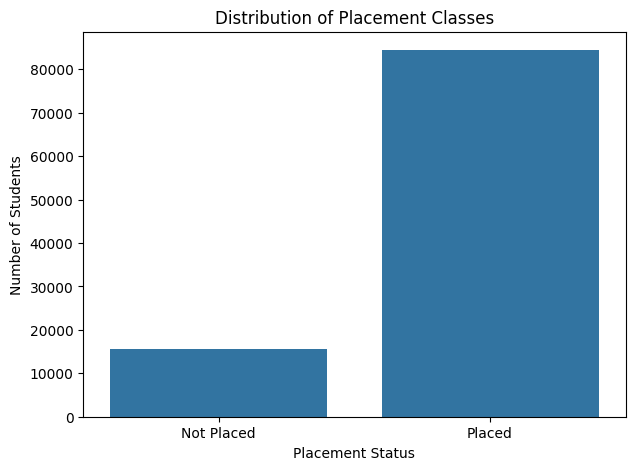

In [14]:
# Target variable or Placement distribution
print("Placement Distribution:")
print(campus_df[target_attribute].value_counts().sort_index())

plt.figure(figsize=(7, 5))

sns.countplot(
    data=campus_df,
    x=target_attribute[0],
    order=[0, 1]
)

plt.title("Distribution of Placement Classes")
plt.xlabel("Placement Status")
plt.ylabel("Number of Students")
plt.xticks(
    ticks=[0, 1],
    labels=["Not Placed", "Placed"]
)

plt.show()

In [15]:
# Placement Percentage
placement_percentage = (
    campus_df['placed'].value_counts(normalize=True, dropna=False) * 100
)
print("Placement Percentage:")
display(placement_percentage.round(2))

Placement Percentage:


,proportion
placed,
1,84.43
0,15.57


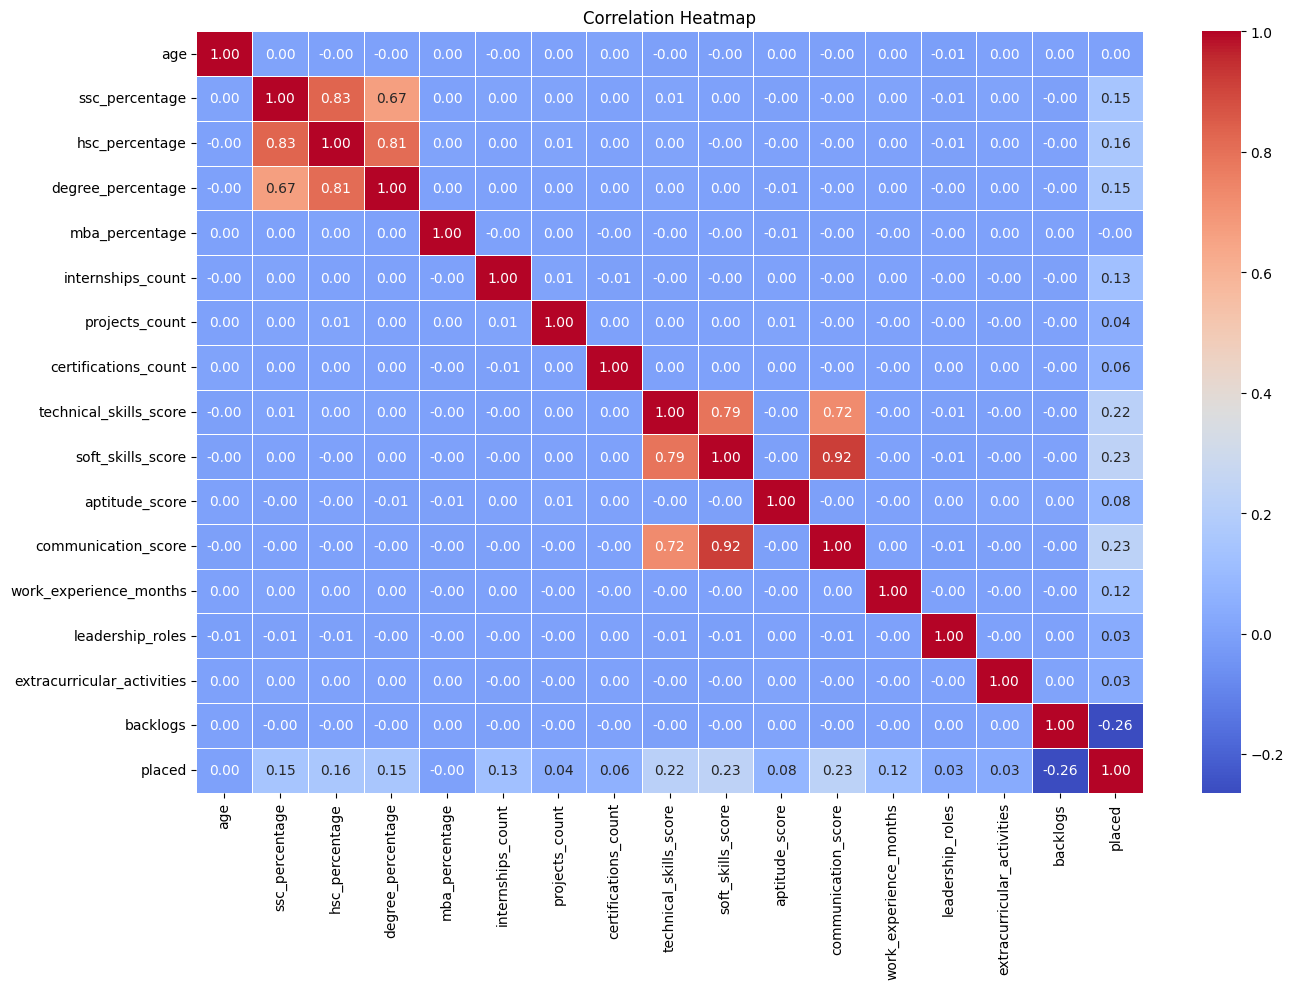

In [16]:
# Correlation analysis
correlation_attributes = [
    'age',
    'ssc_percentage',
    'hsc_percentage',
    'degree_percentage',
    'mba_percentage',
    'internships_count',
    'projects_count',
    'certifications_count',
    'technical_skills_score',
    'soft_skills_score',
    'aptitude_score',
    'communication_score',
    'work_experience_months',
    'leadership_roles',
    'extracurricular_activities',
    'backlogs',
    'placed'
]

correlation_matrix = campus_df[
    correlation_attributes
].corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

* +1 indicates a strong positive linear relationship.



* -1 indicates a strong negative linear relationship.



* 0 indicates little or no linear relationship.

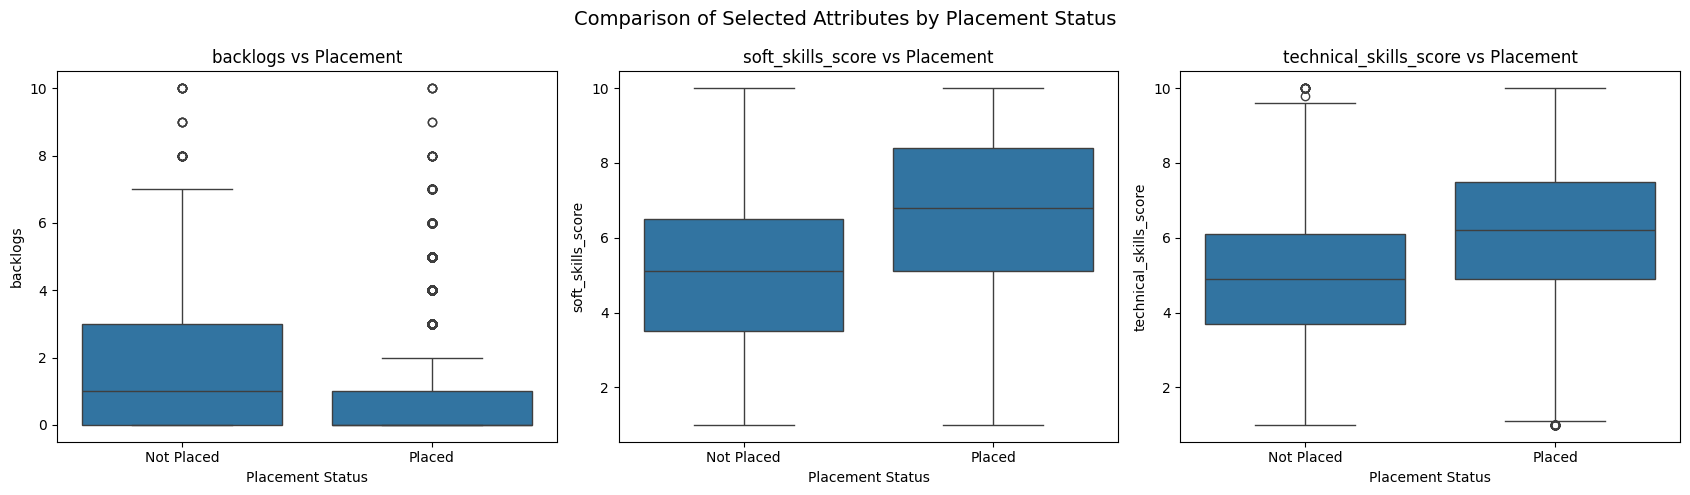

In [17]:
# Placement outcome against selected attributes

selected_attributes = [
    'backlogs',
    'soft_skills_score',
    'technical_skills_score'
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for col, ax in zip(selected_attributes, axes):

    sns.boxplot(
        data=eda_sample,
        x='placed',
        y=col,
        order=[0, 1],
        ax=ax
    )

    ax.set_title(f'{col} vs Placement')
    ax.set_xlabel('Placement Status')
    ax.set_ylabel(col)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Not Placed', 'Placed'])

plt.suptitle(
    'Comparison of Selected Attributes by Placement Status',
    fontsize=14
)

plt.tight_layout()
plt.show()

##### **4. Perform the preprocessing.**

In [18]:
# Create a copy of the dataset
campus_preprocessed = campus_df.copy()

print("Original Dataset Shape:", campus_df.shape)
print("Preprocessing Dataset Shape:", campus_preprocessed.shape)

print("\nOriginal Dataset Memory:",
      round(campus_df.memory_usage(deep=True).sum() / (1024**2), 2), "MB")

print("Preprocessing Dataset Memory:",
      round(campus_preprocessed.memory_usage(deep=True).sum() / (1024**2), 2), "MB")

Original Dataset Shape: (100000, 26)
Preprocessing Dataset Shape: (100000, 26)

Original Dataset Memory: 54.77 MB
Preprocessing Dataset Memory: 54.77 MB


Missing values are values that are not available in a particular attribute.

In this dataset, the `specialization` attribute contains 64,965 missing values.

After examining the relationship between `mba_percentage` and `specialization`, we found that:

* All students with MBA percentage greater than zero have a specialization.
* All students with MBA percentage equal to zero have missing specialization values.

Therefore, these missing values represent students for whom MBA specialization is not applicable.

We replace these missing values with `Not Applicable` instead of deleting the records or replacing them with the most frequent specialization.


In [19]:
# Checking missing values before preprocessing
print("Missing Values Before Preprocessing:")
print(campus_preprocessed.isnull().sum().sum())

Missing Values Before Preprocessing:
64965


In [20]:
# Handling missing values in specialization
campus_preprocessed['specialization'] = (
    campus_preprocessed['specialization'].fillna('Not Applicable')
)

In [21]:
# Checking missing values after preprocessing
print("\nMissing Values After Preprocessing:")
print(campus_preprocessed.isnull().sum().sum())


Missing Values After Preprocessing:
0


In [22]:
print("\nSpecialization Distribution:")
print(campus_preprocessed['specialization'].value_counts())


Specialization Distribution:
specialization
Not Applicable         64965
Marketing & HR         11741
Finance & HR           11675
Marketing & Finance    11619
Name: count, dtype: int64


In [23]:
# Separating input features and target variable

excluded_attributes = [
    'student_id',
    'salary_lpa',
]

campus_preprocessed = campus_preprocessed.drop(columns=excluded_attributes)

X = campus_preprocessed.drop(columns=target_attribute)
y = campus_preprocessed[target_attribute]

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nExcluded Attributes:", excluded_attributes)

print("\nTarget Distribution:")
print(y.value_counts())

Input Features Shape: (100000, 23)
Target Variable Shape: (100000, 1)

Excluded Attributes: ['student_id', 'salary_lpa']

Target Distribution:
placed
1         84432
0         15568
Name: count, dtype: int64


In [24]:
# Selecting numerical predictor features
numerical_features = [
    col for col in numerical_attributes
    if col != 'salary_lpa'
]

# Selecting categorical predictor features
categorical_features = categorical_attributes.copy()

print("Numerical Features:")
display(numerical_features)
print("\nCategorical Features:")
display(categorical_features)

print("\nNumber of Numerical Features:", len(numerical_features))
print("Number of Categorical Features:", len(categorical_features))

print("\nTotal Predictor Features:",
      len(numerical_features) + len(categorical_features))

Numerical Features:


['age',
 'ssc_percentage',
 'hsc_percentage',
 'degree_percentage',
 'mba_percentage',
 'internships_count',
 'projects_count',
 'certifications_count',
 'technical_skills_score',
 'soft_skills_score',
 'aptitude_score',
 'communication_score',
 'work_experience_months',
 'leadership_roles',
 'extracurricular_activities',
 'backlogs']


Categorical Features:


['gender',
 'city_tier',
 'ssc_board',
 'hsc_board',
 'hsc_stream',
 'degree_field',
 'specialization']


Number of Numerical Features: 16
Number of Categorical Features: 7

Total Predictor Features: 23


In [25]:
# Applying One-Hot Encoding to categorical features

campus_encoded = pd.get_dummies(
    campus_preprocessed,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

print("Categorical Encoding Completed Successfully!")

print("\nDataset Shape Before Encoding:",
      campus_preprocessed.shape)

print("Dataset Shape After Encoding:",
      campus_encoded.shape)

display(campus_encoded.head())

Categorical Encoding Completed Successfully!

Dataset Shape Before Encoding: (100000, 24)
Dataset Shape After Encoding: (100000, 34)


,age,ssc_percentage,hsc_percentage,degree_percentage,mba_percentage,internships_count,projects_count,certifications_count,technical_skills_score,soft_skills_score,...,hsc_board_State,hsc_stream_Commerce,hsc_stream_Science,degree_field_Business,degree_field_Engineering,degree_field_Other,degree_field_Science,specialization_Marketing & Finance,specialization_Marketing & HR,specialization_Not Applicable
0,22,71.01,76.76,64.44,0.0,1,2,2,6.8,7.8,...,0,1,0,0,1,0,0,0,0,1
1,22,58.46,57.62,68.24,0.0,1,1,2,4.6,4.8,...,1,0,1,1,0,0,0,0,0,1
2,21,67.83,65.67,52.33,0.0,4,3,2,4.7,5.0,...,1,1,0,0,1,0,0,0,0,1
3,21,80.40,77.15,56.55,0.0,2,3,3,6.8,7.6,...,1,0,1,0,1,0,0,0,0,1
4,21,66.10,62.81,78.93,0.0,1,4,2,7.0,5.7,...,0,0,1,0,1,0,0,0,0,1


In [26]:
# Separating encoded features and target variable

X_encoded = campus_encoded.drop(columns=['placed'])
y_encoded = campus_encoded['placed']

# Checking data types
print("Data Types of Encoded Features:")
print(X_encoded.dtypes.value_counts())

# Checking for non-numerical features
non_numerical_columns = X_encoded.select_dtypes(
    exclude=np.number
).columns.tolist()

print("\nNon-Numerical Columns:", non_numerical_columns)

# Checking missing values
print("\nMissing Values in Encoded Dataset:",
      campus_encoded.isnull().sum().sum())

# Checking target values
print("\nTarget Class Distribution:")
print(y_encoded.value_counts().sort_index())

print("\nEncoded Features Shape:", X_encoded.shape)
print("Target Variable Shape:", y_encoded.shape)

Data Types of Encoded Features:
int64      25
float64     8
Name: count, dtype: int64

Non-Numerical Columns: []

Missing Values in Encoded Dataset: 0

Target Class Distribution:
placed
0    15568
1    84432
Name: count, dtype: int64

Encoded Features Shape: (100000, 33)
Target Variable Shape: (100000,)


In [27]:
# Final dataset verification

print("FINAL PREPROCESSING VERIFICATION")
print("=" * 45)

print("Original Dataset Shape:", campus_df.shape)

print("Final Preprocessed Dataset Shape:",
      campus_encoded.shape)

print("\nNumber of Independent Features:",
      X_encoded.shape[1])

print("Number of Target Attributes:",
      1)

print("\nTotal Missing Values:",
      campus_encoded.isnull().sum().sum())

print("Total Duplicate Records:",
      campus_encoded.duplicated().sum())

print("\nAll Features Numerical:",
      X_encoded.select_dtypes(include=np.number).shape[1]
      == X_encoded.shape[1])

print("\nTarget Values:",
      sorted(y_encoded.unique()))

print("\nTarget Distribution:")
print(y_encoded.value_counts())

FINAL PREPROCESSING VERIFICATION
Original Dataset Shape: (100000, 26)
Final Preprocessed Dataset Shape: (100000, 34)

Number of Independent Features: 33
Number of Target Attributes: 1

Total Missing Values: 0
Total Duplicate Records: 0

All Features Numerical: True

Target Values: [np.int64(0), np.int64(1)]

Target Distribution:
placed
1    84432
0    15568
Name: count, dtype: int64


In [30]:
# Saving the preprocessed dataset

campus_encoded.to_csv(
    'campus_preprocessed.csv',
    index=False
)

print("Preprocessed dataset saved successfully!")
print("Saved Dataset Shape:", campus_preprocessed.shape)

Preprocessed dataset saved successfully!
Saved Dataset Shape: (100000, 24)


##### **5. Write about regression dataset with sample of 10 instances. Also define the size of dataset.**

#### **Uber Fare Prediction Dataset**


The **Uber Fare Prediction Dataset** is a regression dataset obtained from Kaggle. It contains information about Uber trips, including pickup and drop-off locations, pickup date and time, passenger count, and the corresponding fare amount.

The main objective of this dataset is to predict the fare amount of an Uber ride based on the trip-related attributes. Since the output variable, `fare_amount`, is a continuous numerical value, this problem is considered a **Supervised Machine Learning Regression Problem**.

The dataset contains the following information:

- **Number of Instances:** 200,000
- **Number of Attributes:** 9
- **Dataset Shape:** (200000, 9)
- **File Format:** CSV
- **Target Attribute:** `fare_amount`

The dataset includes geographical coordinates of pickup and drop-off locations, trip date and time, passenger count, and fare information. These attributes can help identify factors that influence the cost of an Uber ride.

**Dataset Source:** [Kaggle – Uber Fares Dataset]

https://www.kaggle.com/datasets/yasserh/uber-fares-dataset
https://drive.google.com/file/d/1x_Azaoo0VLKxqBzstVf3pNSGzHDUJZ-q/view?usp=drive_link

In [26]:
# Loading the regression dataset
from google.colab import files
uploaded = files.upload()

uber_df = pd.read_csv('uber.csv')
print("Dataset loaded successfully!")

Saving uber.csv to uber.csv
Dataset loaded successfully!


In [27]:
# 10 sample instances
display(uber_df.head(10))

# Dataset Size
print("Number of Instances:", uber_df.shape[0])
print("Number of Attributes:", uber_df.shape[1])
print("Dataset Size:", uber_df.shape)
print("Memory occupied:", (round(uber_df.memory_usage(deep=True).sum() / (1024**2), 2), "MB"))


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5
5,44470845,2011-02-12 02:27:09.0000006,4.9,2011-02-12 02:27:09 UTC,-73.969019,40.755910,-73.969019,40.755910,1
6,48725865,2014-10-12 07:04:00.0000002,24.5,2014-10-12 07:04:00 UTC,-73.961447,40.693965,-73.871195,40.774297,5
7,44195482,2012-12-11 13:52:00.00000029,2.5,2012-12-11 13:52:00 UTC,0.000000,0.000000,0.000000,0.000000,1
8,15822268,2012-02-17 09:32:00.00000043,9.7,2012-02-17 09:32:00 UTC,-73.975187,40.745767,-74.002720,40.743537,1
9,50611056,2012-03-29 19:06:00.000000273,12.5,2012-03-29 19:06:00 UTC,-74.001065,40.741787,-73.963040,40.775012,1


Number of Instances: 200000
Number of Attributes: 9
Dataset Size: (200000, 9)
Memory occupied: (np.float64(39.04), 'MB')


##### **6. Write on different attributes, type of attributes, number of instances, number of attributes, number of missing data, describe the dataset of regression.**

### Attribute Analysis

The Uber Fare Prediction dataset contains 9 attributes describing different aspects of Uber trips.

These attributes can be categorized into numerical, temporal, and identifier attributes.

- **Numerical attributes:** Represent measurable or countable quantities.
- **Temporal attributes:** Represent date and time information.
- **Identifier attributes:** Uniquely identify individual records or trips.
- **Target attribute:** Represents the continuous value that the regression model aims to predict.

The dataset contains 200,000 instances and 9 attributes.

In [28]:
# Display all attributes
print("All Attributes:")
for i, col in enumerate(uber_df.columns, start=1):
    print(i, col)

All Attributes:
1 Unnamed: 0
2 key
3 fare_amount
4 pickup_datetime
5 pickup_longitude
6 pickup_latitude
7 dropoff_longitude
8 dropoff_latitude
9 passenger_count


In [29]:
# Display attribute types
print("Attribute Data Types:")
uber_df.dtypes

Attribute Data Types:


,0
Unnamed: 0,int64
key,object
fare_amount,float64
pickup_datetime,object
pickup_longitude,float64
pickup_latitude,float64
dropoff_longitude,float64
dropoff_latitude,float64
passenger_count,int64


In [30]:
# Attribute Summary
uber_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


In [31]:
# 1. Identifier attributes
identifier_attributes = [
    'Unnamed: 0',
    'key'
]

# 2. Numerical predictor attributes
numerical_attributes = [
    'pickup_longitude',
    'pickup_latitude',
    'dropoff_longitude',
    'dropoff_latitude',
    'passenger_count'
]

# 3. Temporal attributes
temporal_attributes = [
    'pickup_datetime'
]

# 4. Target attribute
target_attribute = [
    'fare_amount'
]

print("IDENTIFIER ATTRIBUTES:")
display(identifier_attributes)

print("\nNUMERICAL ATTRIBUTES:")
display(numerical_attributes)

print("\nTEMPORAL ATTRIBUTES:")
display(temporal_attributes)

print("\nTARGET ATTRIBUTE:")
display(target_attribute)

print("\nATTRIBUTE COUNT SUMMARY:")

print("Identifier Attributes:", len(identifier_attributes))
print("Numerical Attributes:", len(numerical_attributes))
print("Temporal Attributes:", len(temporal_attributes))
print("Target Attributes:", len(target_attribute))

total = (
    len(identifier_attributes) +
    len(numerical_attributes) +
    len(temporal_attributes) +
    len(target_attribute)
)

print("\nTotal Number of Attributes:", total)

IDENTIFIER ATTRIBUTES:


['Unnamed: 0', 'key']


NUMERICAL ATTRIBUTES:


['pickup_longitude',
 'pickup_latitude',
 'dropoff_longitude',
 'dropoff_latitude',
 'passenger_count']


TEMPORAL ATTRIBUTES:


['pickup_datetime']


TARGET ATTRIBUTE:


['fare_amount']


ATTRIBUTE COUNT SUMMARY:
Identifier Attributes: 2
Numerical Attributes: 5
Temporal Attributes: 1
Target Attributes: 1

Total Number of Attributes: 9


**Attribute Classification:**

1. **Identifier Attributes:**
   - `Unnamed: 0`: Represents an index-like identifier associated with each record.
   - `key`: Uniquely identifies an Uber trip.

2. **Numerical Attributes:**
   - `pickup_longitude` and `pickup_latitude`: Represent the geographical coordinates of the pickup location.
   - `dropoff_longitude` and `dropoff_latitude`: Represent the geographical coordinates of the drop-off location.
   - `passenger_count`: Represents the number of passengers in the trip.

3. **Temporal Attribute:**
   - `pickup_datetime`: Represents the date and time when the passenger was picked up.

4. **Target Attribute:**
   - `fare_amount`: Represents the fare charged for the Uber trip and is the value to be predicted by the regression model.

In [32]:
# Missing values
missing_values = uber_df.isnull().sum()
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': (missing_values / len(uber_df) * 100).round(2)
})

display(missing_summary)
print("Total Missing Values:", missing_values.sum())
print("Total Missing Percentage:", round(missing_values.sum() / uber_df.size * 100, 2), "%")

,Missing Values,Missing Percentage
Unnamed: 0,0,0.0
key,0,0.0
fare_amount,0,0.0
pickup_datetime,0,0.0
pickup_longitude,0,0.0
pickup_latitude,0,0.0
dropoff_longitude,1,0.0
dropoff_latitude,1,0.0
passenger_count,0,0.0


Total Missing Values: 2
Total Missing Percentage: 0.0 %


In [33]:
# Dataset Description
uber_df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,200000.0,NaN,NaN,NaN,27712503.68235,16013822.212829,1.0,13825346.25,27745495.0,41555300.75,55423567.0
key,200000,200000,2015-05-07 19:52:06.0000003,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fare_amount,200000.0,NaN,NaN,NaN,11.359955,9.901776,-52.0,6.0,8.5,12.5,499.0
pickup_datetime,200000,196629,2009-02-12 12:46:00 UTC,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pickup_longitude,200000.0,NaN,NaN,NaN,-72.527638,11.437787,-1340.64841,-73.992065,-73.981823,-73.967154,57.418457
pickup_latitude,200000.0,NaN,NaN,NaN,39.935885,7.720539,-74.015515,40.734796,40.752592,40.767158,1644.421482
dropoff_longitude,199999.0,NaN,NaN,NaN,-72.525292,13.117408,-3356.6663,-73.991407,-73.980093,-73.963658,1153.572603
dropoff_latitude,199999.0,NaN,NaN,NaN,39.92389,6.794829,-881.985513,40.733823,40.753042,40.768001,872.697628
passenger_count,200000.0,NaN,NaN,NaN,1.684535,1.385997,0.0,1.0,1.0,2.0,208.0


##### **7. Perform the EDA.**

In [34]:
# Check duplicate records
print("Number of Duplicate Rows:",
      uber_df.duplicated().sum())
print("\nNumber of Duplicate Trip Keys:",
      uber_df['key'].duplicated().sum())

Number of Duplicate Rows: 0

Number of Duplicate Trip Keys: 0


In [35]:
# Creating EDA sample
eda_sample = uber_df.sample(
    n=min(10000, len(uber_df)),
    random_state=42
)

print("Original Dataset Shape:", uber_df.shape)
print("EDA Sample Shape:", eda_sample.shape)

Original Dataset Shape: (200000, 9)
EDA Sample Shape: (10000, 9)


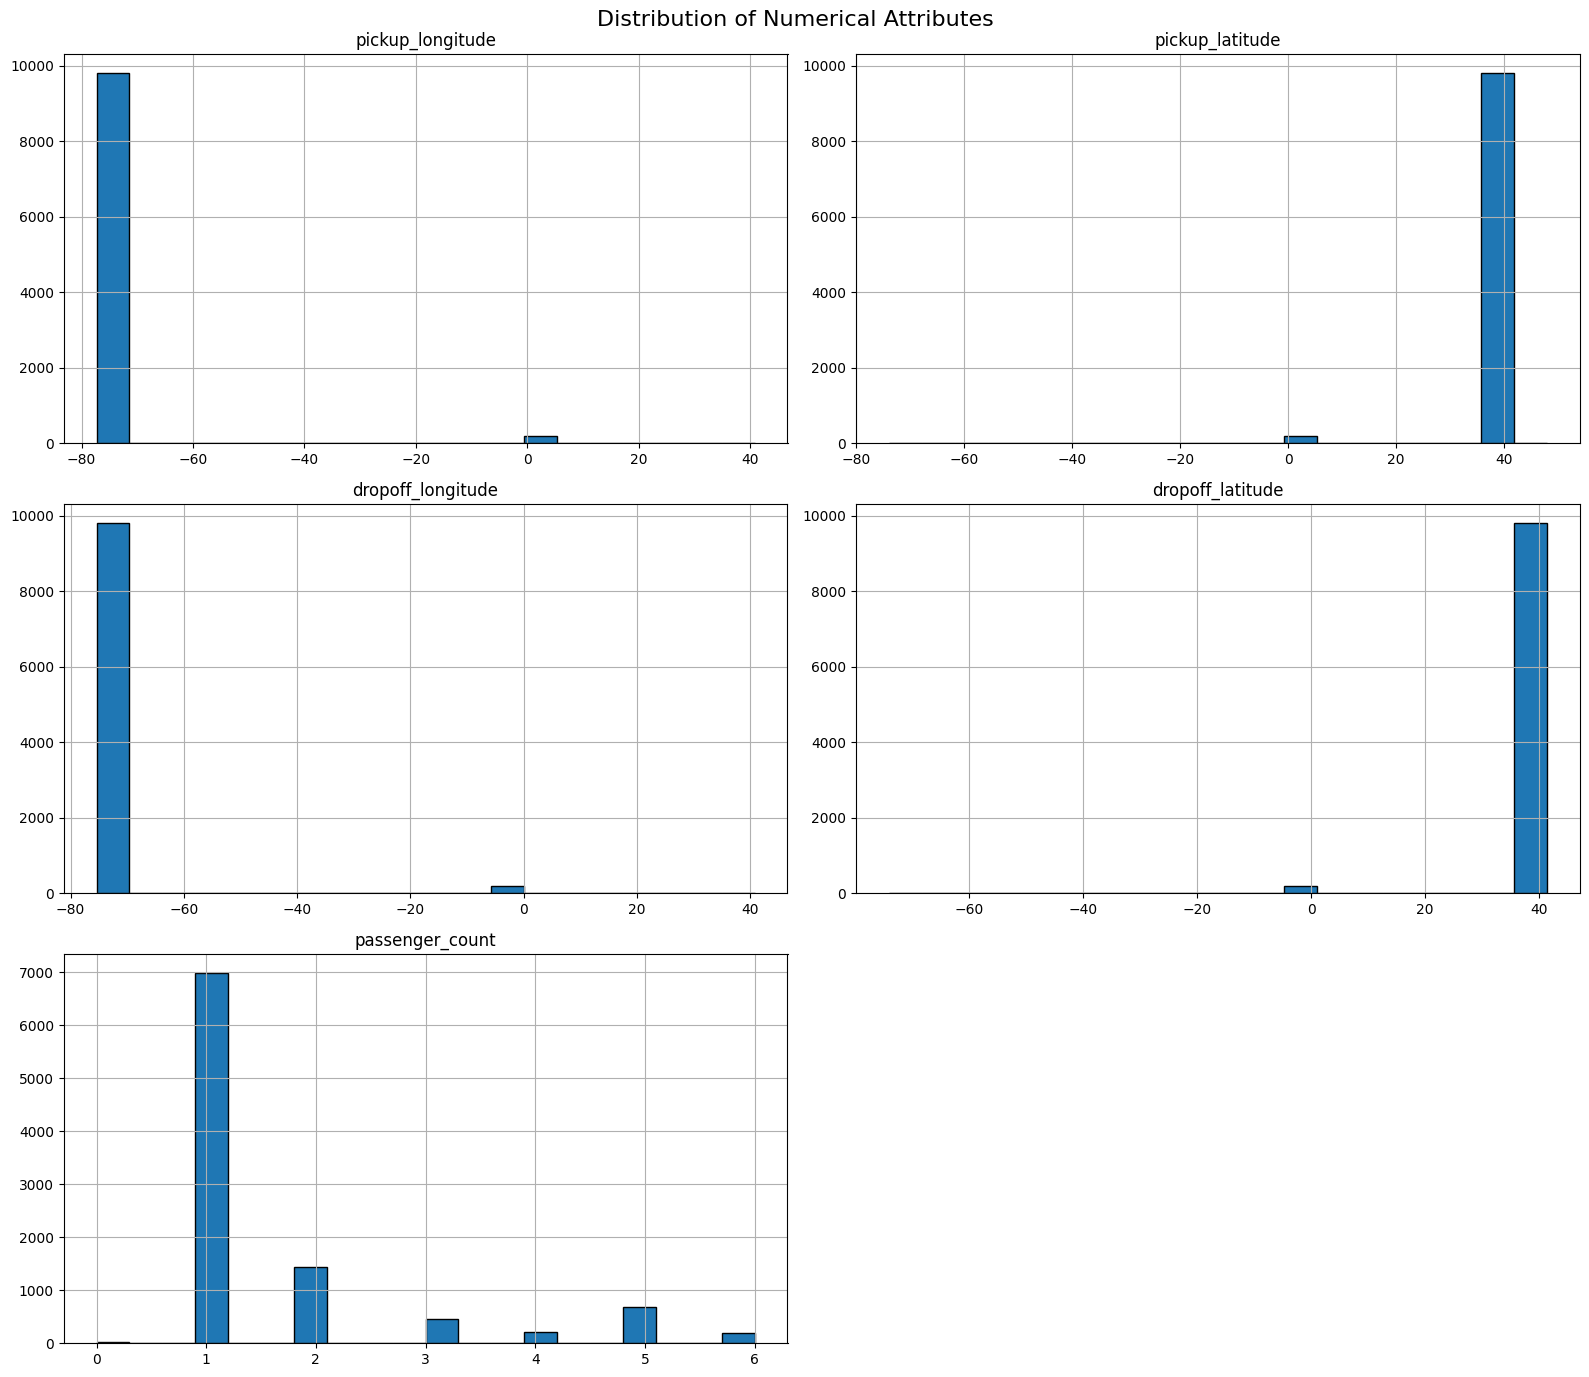

In [36]:
# Numerical attribute distribution
eda_sample[numerical_attributes].hist(
    figsize=(16, 14),
    bins=20,
    edgecolor='black'
)

plt.suptitle(
    "Distribution of Numerical Attributes",
    fontsize=16
)

plt.tight_layout()
plt.show()

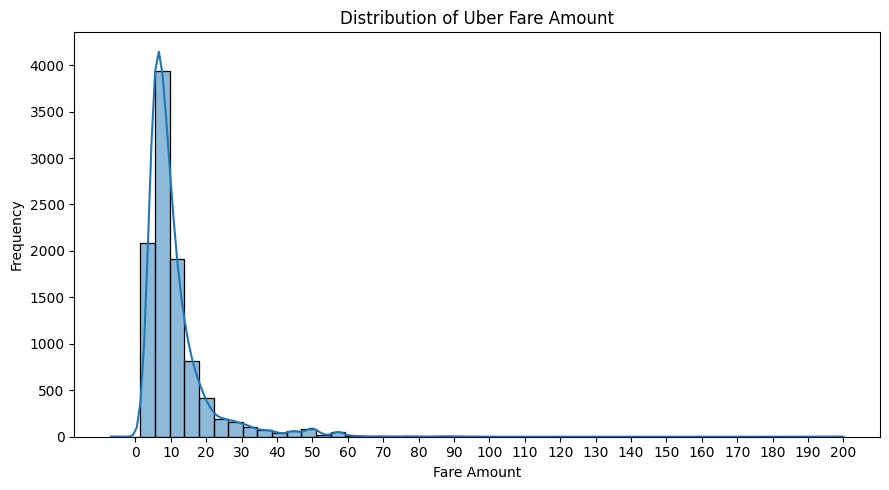

In [37]:
# Target variable or fare amount distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    data=eda_sample,
    x='fare_amount',
    bins=50,
    kde=True
)

plt.title("Distribution of Uber Fare Amount")
plt.xlabel("Fare Amount")
plt.ylabel("Frequency")
plt.xticks(np.arange(0, 210, 10))

plt.tight_layout()
plt.show()

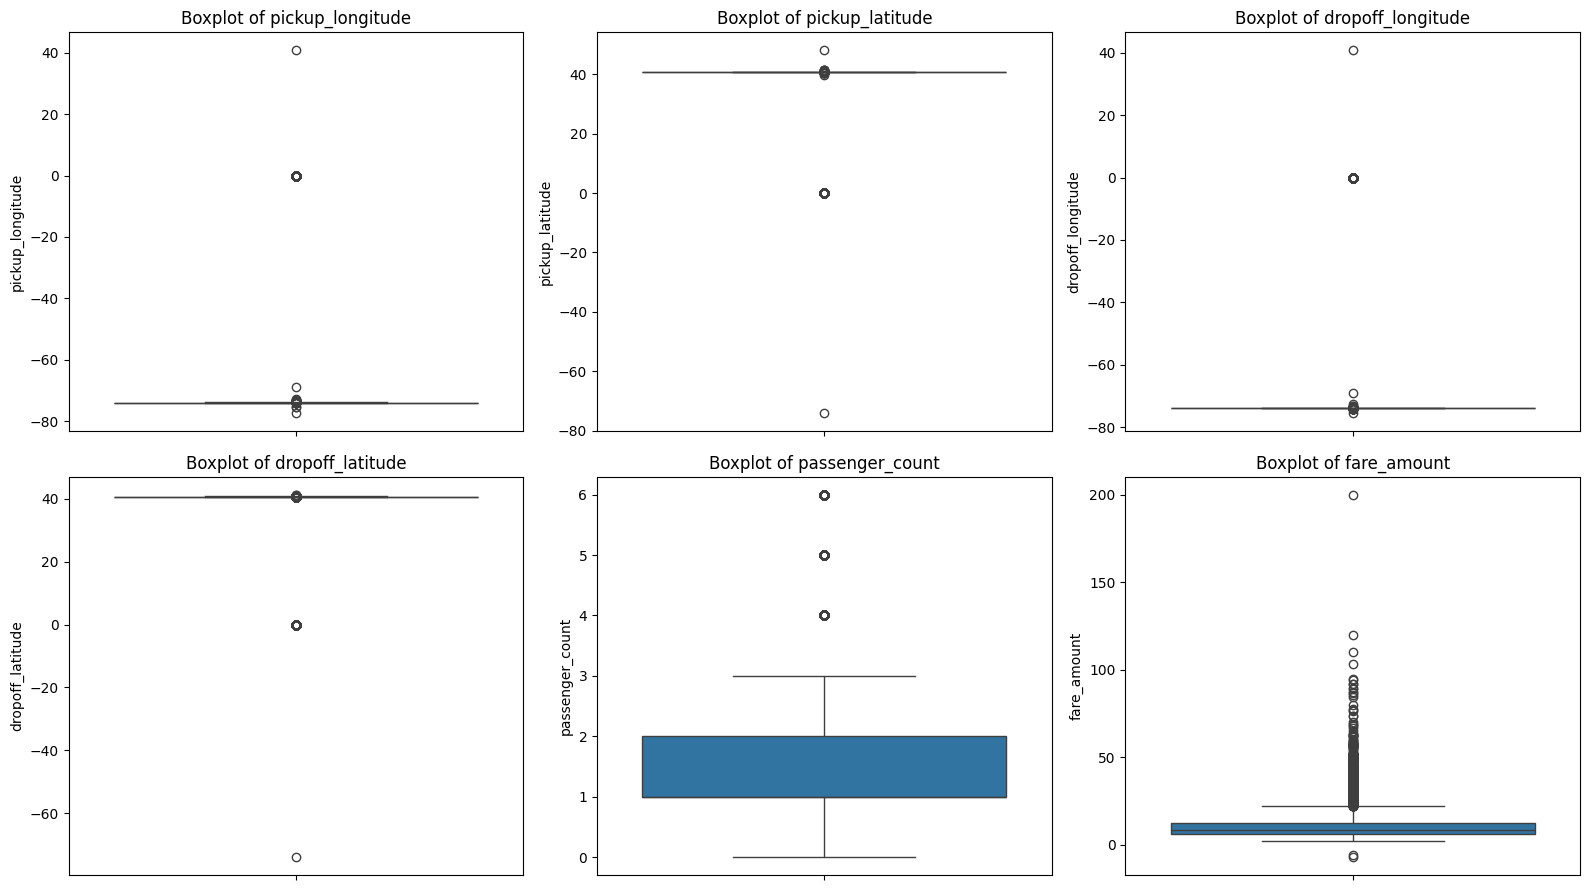

In [38]:
# Boxplots for numerical attributes

# Combine numerical predictors and target attribute for plotting
plot_attributes = numerical_attributes + target_attribute

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9)
)

for col, ax in zip(
    plot_attributes,
    axes.flatten()
):
    sns.boxplot(
        data=eda_sample,
        y=col,
        ax=ax
    )

    ax.set_title(f"Boxplot of {col}")
    ax.set_ylabel(col)

# Hide any unused subplots (if any are left empty)
for ax in axes.flatten()[len(plot_attributes):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [39]:
# Creating a separate copy for date-time analysis
eda_datetime = eda_sample.copy()

In [40]:
# Converting pickup_datetime into datetime format
eda_datetime['pickup_datetime'] = pd.to_datetime(
    eda_datetime['pickup_datetime'],
    utc=True
)

In [41]:
# Extracting date and time components
eda_datetime['pickup_year'] = (
    eda_datetime['pickup_datetime'].dt.year
)
eda_datetime['pickup_month'] = (
    eda_datetime['pickup_datetime'].dt.month
)
eda_datetime['pickup_day'] = (
    eda_datetime['pickup_datetime'].dt.day
)
eda_datetime['pickup_dayofweek'] = (
    eda_datetime['pickup_datetime'].dt.dayofweek
)
eda_datetime['pickup_hour'] = (
    eda_datetime['pickup_datetime'].dt.hour
)

print("Extracted Date and Time Attributes:")
display(
    eda_datetime[
        [
            'pickup_year',
            'pickup_month',
            'pickup_day',
            'pickup_dayofweek',
            'pickup_hour'
        ]
    ].head()
)

Extracted Date and Time Attributes:


,pickup_year,pickup_month,pickup_day,pickup_dayofweek,pickup_hour
119737,2014,12,8,0,23
72272,2012,9,2,6,21
158154,2010,6,24,3,18
65426,2012,11,14,2,20
30074,2011,9,19,0,8


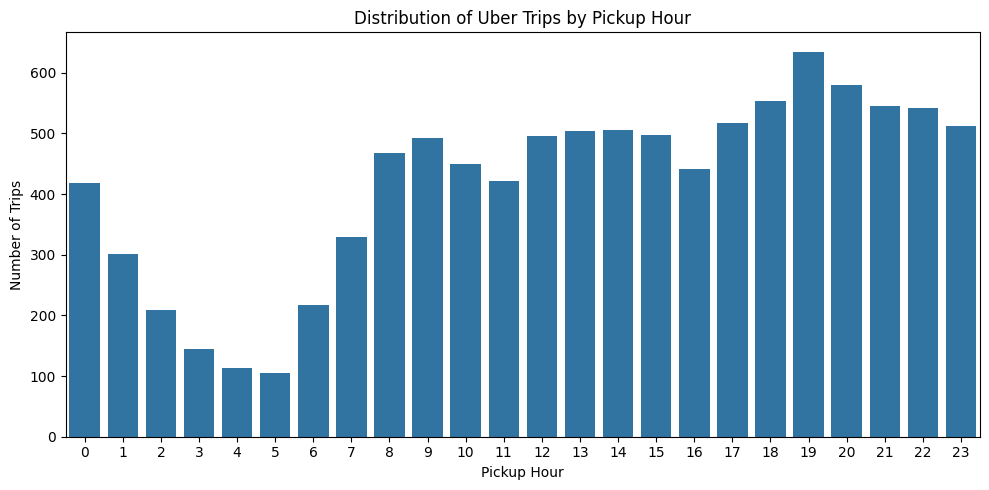

In [42]:
# Distribution of trips by pickup hour
plt.figure(figsize=(10, 5))

sns.countplot(
    data=eda_datetime,
    x='pickup_hour',
    order=sorted(eda_datetime['pickup_hour'].unique())
)

plt.title("Distribution of Uber Trips by Pickup Hour")
plt.xlabel("Pickup Hour")
plt.ylabel("Number of Trips")

plt.tight_layout()
plt.show()

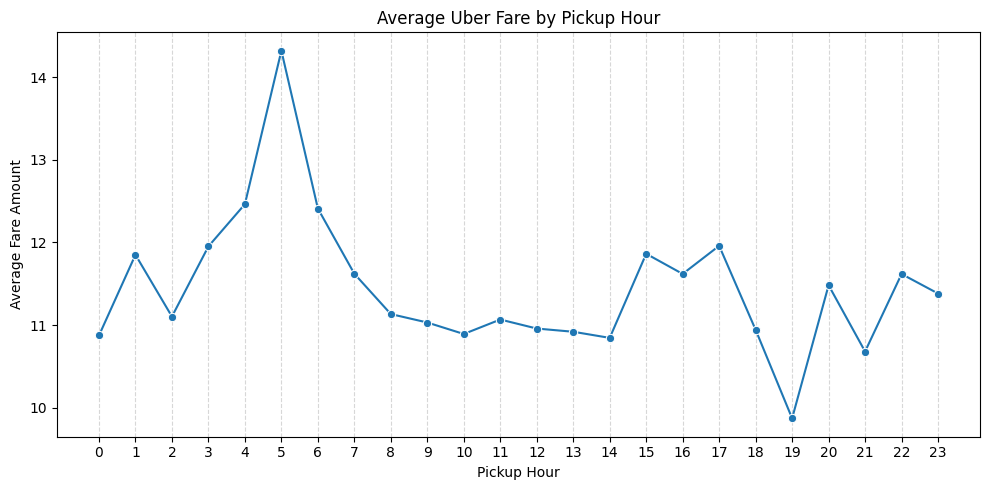

In [43]:
# Average fare amount by pickup hour
hourly_fare = (
    eda_datetime.groupby('pickup_hour')['fare_amount']
    .mean()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=hourly_fare.index,
    y=hourly_fare.values,
    marker='o'
)

plt.title("Average Uber Fare by Pickup Hour")
plt.xlabel("Pickup Hour")
plt.ylabel("Average Fare Amount")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.xticks(range(0, 24))

plt.tight_layout()
plt.show()

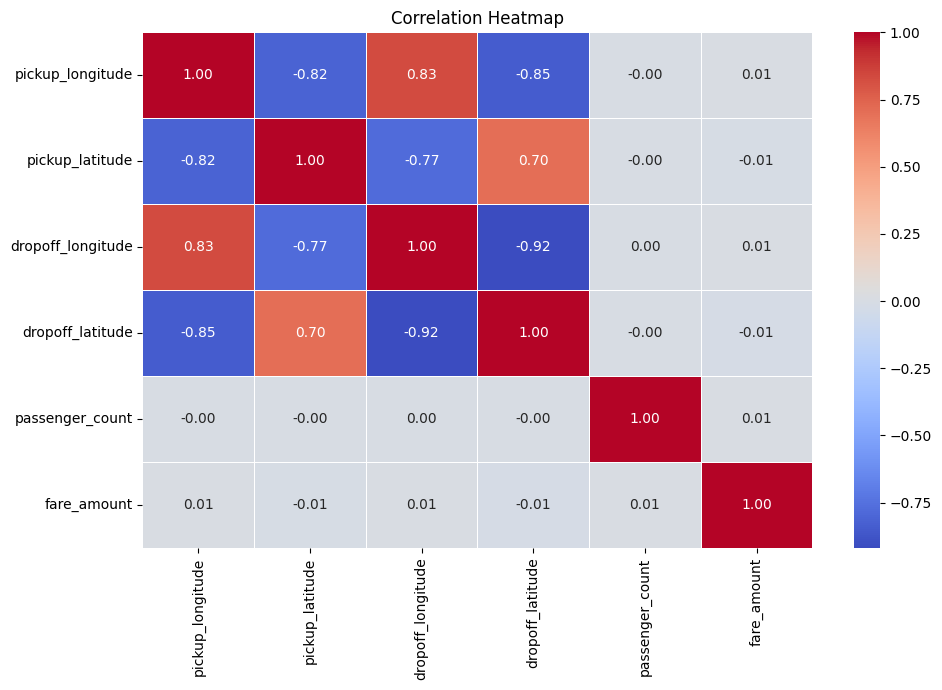

In [44]:
# Correlation analysis

correlation_attributes = (
    numerical_attributes + target_attribute
)

correlation_matrix = uber_df[
    correlation_attributes
].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

* +1 indicates a perfect positive linear relationship.

* -1 indicates a perfect negative linear relationship.

* 0 indicates little or no linear relationship.

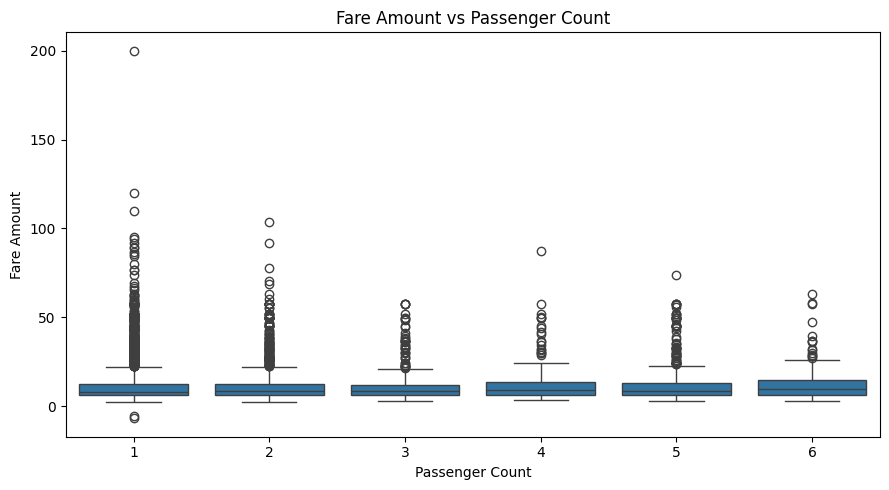

In [45]:
# Relationship between passenger count and fare amount

valid_passenger_sample = eda_sample[
    eda_sample['passenger_count'].between(1, 6)
]

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=valid_passenger_sample,
    x='passenger_count',
    y='fare_amount',
    order=[1, 2, 3, 4, 5, 6]
)

plt.title("Fare Amount vs Passenger Count")
plt.xlabel("Passenger Count")
plt.ylabel("Fare Amount")

plt.tight_layout()
plt.show()

In [46]:
# Checking unusual values

print("Negative Fare Amounts:")
print((uber_df['fare_amount'] < 0).sum())

print("\nZero Passenger Counts:")
print((uber_df['passenger_count'] == 0).sum())

print("\nPassenger Counts Greater Than 6:")
print((uber_df['passenger_count'] > 6).sum())

print("\nZero Pickup Coordinates:")
print(
    (
        (uber_df['pickup_longitude'] == 0) |
        (uber_df['pickup_latitude'] == 0)
    ).sum()
)

print("\nZero Drop-off Coordinates:")
print(
    (
        (uber_df['dropoff_longitude'] == 0) |
        (uber_df['dropoff_latitude'] == 0)
    ).sum()
)

Negative Fare Amounts:
17

Zero Passenger Counts:
709

Passenger Counts Greater Than 6:
1

Zero Pickup Coordinates:
3789

Zero Drop-off Coordinates:
3766


##### **8. Perform the preprocessing.**

In [47]:
# Creating a separate copy of the dataset
uber_preprocessed = uber_df.copy()

print("Original Dataset Shape:", uber_df.shape)
print("Preprocessing Dataset Shape:", uber_preprocessed.shape)

print("\nOriginal Dataset Memory:",
      round(uber_df.memory_usage(deep=True).sum() / (1024**2), 2), "MB")

print("Preprocessing Dataset Memory:",
      round(uber_preprocessed.memory_usage(deep=True).sum() / (1024**2), 2), "MB")

Original Dataset Shape: (200000, 9)
Preprocessing Dataset Shape: (200000, 9)

Original Dataset Memory: 39.04 MB
Preprocessing Dataset Memory: 39.04 MB


In [48]:
# Checking missing values before preprocessing
print("Missing Values Before Preprocessing:")
print(uber_preprocessed.isnull().sum())

print("\nTotal Missing Values:",
      uber_preprocessed.isnull().sum().sum())

Missing Values Before Preprocessing:
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

Total Missing Values: 2


In [49]:
# Displaying records containing missing values
missing_records = uber_df[
    uber_df.isnull().any(axis=1)
]

display(missing_records)
print("Number of affected rows:", len(missing_records))

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
87946,32736015,2013-07-02 03:51:57.0000001,24.1,2013-07-02 03:51:57 UTC,-73.950581,40.779692,NaN,NaN,0


Number of affected rows: 1


In [50]:
# Removing records with missing values
uber_preprocessed = uber_preprocessed.dropna().copy()

In [51]:
# Checking missing values after preprocessing
print("Missing Values After Preprocessing:")
print(uber_preprocessed.isnull().sum().sum())
print("\nDataset Shape After Handling Missing Values:",
      uber_preprocessed.shape)

Missing Values After Preprocessing:
0

Dataset Shape After Handling Missing Values: (199999, 9)


In [52]:
# Converting pickup_datetime into datetime format

uber_preprocessed['pickup_datetime'] = pd.to_datetime(
    uber_preprocessed['pickup_datetime'],
    utc=True,
    errors='coerce'
)

print("Pickup Datetime Data Type:",
      uber_preprocessed['pickup_datetime'].dtype)

print("\nInvalid Datetime Values:",
      uber_preprocessed['pickup_datetime'].isnull().sum())

print("\nSample Pickup Datetime Values:")
display(uber_preprocessed['pickup_datetime'].head())

Pickup Datetime Data Type: datetime64[ns, UTC]

Invalid Datetime Values: 0

Sample Pickup Datetime Values:


,pickup_datetime
0,2015-05-07 19:52:06+00:00
1,2009-07-17 20:04:56+00:00
2,2009-08-24 21:45:00+00:00
3,2009-06-26 08:22:21+00:00
4,2014-08-28 17:47:00+00:00


* utc=True: Converts the datetime values to UTC timezone-aware timestamps.



* errors='coerce': Converts invalid datetime values into NaT (Not a Time) instead of raising an error.



* pd.to_datetime(): Converts the column into datetime format.

In [53]:
# Removing invalid records

# Defining valid geographical coordinates
valid_pickup = (
    uber_preprocessed['pickup_longitude'].between(-74.3, -73.6) &
    uber_preprocessed['pickup_latitude'].between(40.5, 41.0)
)
valid_dropoff = (
    uber_preprocessed['dropoff_longitude'].between(-74.3, -73.6) &
    uber_preprocessed['dropoff_latitude'].between(40.5, 41.0)
)

# Defining valid records
valid_records = (
    (uber_preprocessed['fare_amount'] > 0) &
    (uber_preprocessed['passenger_count'].between(1, 6)) &
    valid_pickup &
    valid_dropoff &
    uber_preprocessed['pickup_datetime'].notnull()
)

# Counting records before cleaning
records_before_cleaning = len(uber_preprocessed)

# Keeping only valid records
uber_preprocessed = uber_preprocessed.loc[
    valid_records
].copy()

# Displaying cleaning results
print("Records Before Cleaning:", records_before_cleaning)
print("Records After Cleaning:", len(uber_preprocessed))

print("Records Removed:",
      records_before_cleaning - len(uber_preprocessed))

print("\nDataset Shape After Cleaning:",
      uber_preprocessed.shape)

Records Before Cleaning: 199999
Records After Cleaning: 194918
Records Removed: 5081

Dataset Shape After Cleaning: (194918, 9)


In [54]:
# Extracting date and time features from pickup_datetime

uber_preprocessed['pickup_year'] = (
    uber_preprocessed['pickup_datetime'].dt.year
)

uber_preprocessed['pickup_month'] = (
    uber_preprocessed['pickup_datetime'].dt.month
)

uber_preprocessed['pickup_day'] = (
    uber_preprocessed['pickup_datetime'].dt.day
)

uber_preprocessed['pickup_dayofweek'] = (
    uber_preprocessed['pickup_datetime'].dt.dayofweek
)

uber_preprocessed['pickup_hour'] = (
    uber_preprocessed['pickup_datetime'].dt.hour
)

print("Extracted Date and Time Features:")

display(
    uber_preprocessed[
        [
            'pickup_year',
            'pickup_month',
            'pickup_day',
            'pickup_dayofweek',
            'pickup_hour'
        ]
    ].head()
)

print("\nDataset Shape After Feature Extraction:",
      uber_preprocessed.shape)

Extracted Date and Time Features:


,pickup_year,pickup_month,pickup_day,pickup_dayofweek,pickup_hour
0,2015,5,7,3,19
1,2009,7,17,4,20
2,2009,8,24,0,21
3,2009,6,26,4,8
4,2014,8,28,3,17



Dataset Shape After Feature Extraction: (194918, 14)


In [55]:
# Removing unnecessary identifier and original datetime attributes

excluded_attributes = [
    'Unnamed: 0',
    'key',
    'pickup_datetime'
]

uber_preprocessed = uber_preprocessed.drop(
    columns=excluded_attributes
)

print("Removed Attributes:", excluded_attributes)

print("\nRemaining Attributes:")
display(uber_preprocessed.columns.tolist())

print("\nDataset Shape After Removing Unnecessary Attributes:",
      uber_preprocessed.shape)

display(uber_preprocessed.head())

Removed Attributes: ['Unnamed: 0', 'key', 'pickup_datetime']

Remaining Attributes:


['fare_amount',
 'pickup_longitude',
 'pickup_latitude',
 'dropoff_longitude',
 'dropoff_latitude',
 'passenger_count',
 'pickup_year',
 'pickup_month',
 'pickup_day',
 'pickup_dayofweek',
 'pickup_hour']


Dataset Shape After Removing Unnecessary Attributes: (194918, 11)


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,pickup_year,pickup_month,pickup_day,pickup_dayofweek,pickup_hour
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,2015,5,7,3,19
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,2009,7,17,4,20
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,2009,8,24,0,21
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,2009,6,26,4,8
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,2014,8,28,3,17


In [56]:
# Separating independent and dependent variables
X = uber_preprocessed.drop(
    columns=['fare_amount']
)
y = uber_preprocessed['fare_amount']

print("Independent Variables (X):")
display(X.head())
print("\nDependent Variable (y):")
display(y.head())

print("\nShape of X:", X.shape)
print("Shape of y:", y.shape)

Independent Variables (X):


,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,pickup_year,pickup_month,pickup_day,pickup_dayofweek,pickup_hour
0,-73.999817,40.738354,-73.999512,40.723217,1,2015,5,7,3,19
1,-73.994355,40.728225,-73.994710,40.750325,1,2009,7,17,4,20
2,-74.005043,40.740770,-73.962565,40.772647,1,2009,8,24,0,21
3,-73.976124,40.790844,-73.965316,40.803349,3,2009,6,26,4,8
4,-73.925023,40.744085,-73.973082,40.761247,5,2014,8,28,3,17



Dependent Variable (y):


,fare_amount
0,7.5
1,7.7
2,12.9
3,5.3
4,16.0



Shape of X: (194918, 10)
Shape of y: (194918,)


In [57]:
# Identifying numerical features from independent variables

numerical_features = X.columns.tolist()

print("Numerical Features:")
display(numerical_features)

print("\nNumber of Numerical Features:",
      len(numerical_features))

print("\nData Types of Features:")
display(X.dtypes)

Numerical Features:


['pickup_longitude',
 'pickup_latitude',
 'dropoff_longitude',
 'dropoff_latitude',
 'passenger_count',
 'pickup_year',
 'pickup_month',
 'pickup_day',
 'pickup_dayofweek',
 'pickup_hour']


Number of Numerical Features: 10

Data Types of Features:


,0
pickup_longitude,float64
pickup_latitude,float64
dropoff_longitude,float64
dropoff_latitude,float64
passenger_count,int64
pickup_year,int32
pickup_month,int32
pickup_day,int32
pickup_dayofweek,int32
pickup_hour,int32


In [58]:
# Saving the preprocessed dataset

uber_preprocessed.to_csv(
    'uber_preprocessed.csv',
    index=False
)

print("Preprocessed dataset saved successfully!")
print("Saved Dataset Shape:", uber_preprocessed.shape)

Preprocessed dataset saved successfully!
Saved Dataset Shape: (194918, 11)


# Srabani Khuntia, 24BCSB03
# Roll No: 7, Group:E1